In [8]:
import numpy as np
import rasterio
from rasterio.warp import transform_bounds, Resampling
from rasterio.windows import from_bounds
from rasterio.transform import from_origin
import planetary_computer
import geoai
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data"); RESULTS = Path("../results")
for p in [DATA / "processed", RESULTS]:
    p.mkdir(parents=True, exist_ok=True)

BBOX = [24.55, 36.88, 24.82, 37.10]
CRS = "EPSG:32635"
RES = 10
minx, miny, maxx, maxy = transform_bounds("EPSG:4326", CRS, *BBOX)
left, bottom = np.floor(minx / RES) * RES, np.floor(miny / RES) * RES
right, top = np.ceil(maxx / RES) * RES, np.ceil(maxy / RES) * RES
width, height = int((right - left) / RES), int((top - bottom) / RES)
transform = from_origin(left, top, RES, RES)
BANDS = ["B02", "B03", "B04", "B08"]
BAD_SCL = [0, 1, 3, 8, 9, 10]

def read_band(item, asset):
    with rasterio.open(item.assets[asset].href) as src:
        win = from_bounds(left, bottom, right, top, src.transform)
        return src.read(1, window=win, out_shape=(height, width),
                        resampling=Resampling.nearest, boundless=True, fill_value=0)

def baseline(item):
    return float(item.properties.get("s2:processing_baseline", "0") or 0)

def harmonise(arr, item):
    if baseline(item) >= 4.0:
        return np.where(arr > 0, np.clip(arr.astype("int32") - 1000, 1, None), 0).astype("uint16")
    return arr

def build_s2_composite(time_range, out_path, cloud_lt=30, max_scenes=10):
    items = geoai.pc_stac_search(collection="sentinel-2-l2a", bbox=BBOX, time_range=time_range,
                                 query={"eo:cloud_cover": {"lt": cloud_lt}}, max_items=50)
    items = sorted(items, key=lambda i: i.properties["eo:cloud_cover"])
    print(len(items), "scenes found for", time_range)
    stack = np.zeros((len(BANDS), height, width), dtype="uint16")
    filled = np.zeros((height, width), dtype=bool)
    for item in items[:max_scenes]:
        epsg = item.properties.get("proj:epsg") or str(item.properties.get("proj:code", "")).replace("EPSG:", "")
        if epsg and int(epsg) != 32635:
            continue
        item = planetary_computer.sign(item)
        scl = read_band(item, "SCL")
        red = read_band(item, "B04")
        good = (~np.isin(scl, BAD_SCL)) & (red > 0) & (~filled)
        if good.sum() == 0:
            continue
        for k, b in enumerate(BANDS):
            arr = red if b == "B04" else read_band(item, b)
            stack[k][good] = harmonise(arr, item)[good]
        filled |= good
        print(item.datetime.date(), "- island covered so far:", round(filled.mean() * 100, 1), "%")
        if filled.mean() > 0.995:
            break
        # second pass: fill leftover holes (often bright buildings the cloud mask wrongly flagged)
    for item in items[:max_scenes]:
        epsg = item.properties.get("proj:epsg") or str(item.properties.get("proj:code", "")).replace("EPSG:", "")
        if epsg and int(epsg) != 32635:
            continue
        item = planetary_computer.sign(item)
        red = read_band(item, "B04")
        good = (red > 0) & (~filled)
        if good.sum() == 0:
            continue
        for k, b in enumerate(BANDS):
            arr = red if b == "B04" else read_band(item, b)
            stack[k][good] = harmonise(arr, item)[good]
        filled |= good
        print(item.datetime.date(), "- second pass, covered:", round(filled.mean() * 100, 1), "%")    
    with rasterio.open(out_path, "w", driver="GTiff", height=height, width=width, count=len(BANDS),
                       dtype="uint16", crs=CRS, transform=transform, nodata=0, compress="deflate") as dst:
        dst.write(stack)
    print("saved", out_path)
    return stack

In [9]:
s2_2016 = build_s2_composite("2016-07-15/2016-09-30", DATA / "processed" / "s2_2016_sifnos.tif", cloud_lt=60, max_scenes=20)
s2_2021 = build_s2_composite("2021-08-15/2021-09-15", DATA / "processed" / "s2_2021_sifnos.tif")
s2_2026 = build_s2_composite("2026-08-15/2026-09-15", DATA / "processed" / "s2_2026_sifnos.tif")

50 scenes found for 2016-07-15/2016-09-30
2016-09-15 - island covered so far: 14.5 %
2016-09-05 - island covered so far: 15.7 %
2016-07-27 - island covered so far: 16.0 %
2016-08-16 - island covered so far: 16.3 %
2016-08-06 - island covered so far: 16.4 %
2016-08-29 - island covered so far: 17.8 %
2016-07-30 - island covered so far: 65.0 %
2016-08-29 - island covered so far: 65.0 %
2016-07-30 - island covered so far: 99.9 %
2016-08-06 - second pass, covered: 99.9 %
2016-07-30 - second pass, covered: 100.0 %
2016-07-30 - second pass, covered: 100.0 %
saved ../data/processed/s2_2016_sifnos.tif
40 scenes found for 2021-08-15/2021-09-15
2021-08-25 - island covered so far: 15.3 %
2021-08-20 - island covered so far: 15.7 %
2021-08-15 - island covered so far: 16.2 %
2021-08-30 - island covered so far: 16.2 %
2021-08-18 - island covered so far: 65.0 %
2021-08-28 - island covered so far: 65.0 %
2021-08-28 - island covered so far: 65.0 %
2021-08-28 - island covered so far: 99.9 %
2021-08-25 - s

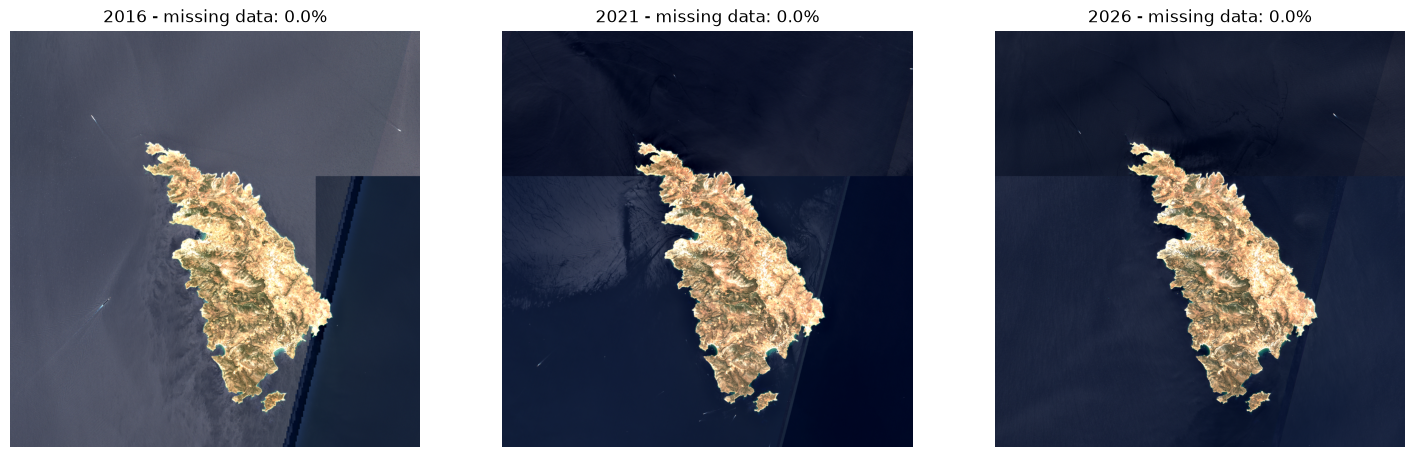

In [10]:
ref = np.stack([s2_2021[2], s2_2021[1], s2_2021[0]], axis=-1).astype("float32")
low, high = np.percentile(ref[ref > 0], (2, 98))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, stack, year in zip(axes, [s2_2016, s2_2021, s2_2026], ["2016", "2021", "2026"]):
    img = np.stack([stack[2], stack[1], stack[0]], axis=-1).astype("float32")
    img = np.clip((img - low) / (high - low), 0, 1)
    img[stack[2] == 0] = [1, 0, 1]
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(year + " - missing data: " + str(round((stack[2] == 0).mean() * 100, 1)) + "%")
plt.savefig(RESULTS / "s2_three_years.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
from rasterio.warp import reproject            # R equivalent: terra::project()

# 1. find the WorldCover map for Sifnos in the catalogue
wc_items = geoai.pc_stac_search(collection="esa-worldcover", bbox=BBOX,
                                time_range="2020-01-01/2021-12-31", max_items=20)
for i in wc_items:
    print(i.id, i.properties.get("start_datetime"))            # show what is available
wc_2021 = [i for i in wc_items if str(i.properties.get("start_datetime", ""))[:4] == "2021"]   # keep the 2021 one
print(len(wc_2021), "WorldCover item(s) for 2021")

# 2. line it up with your Sentinel-2 grid (same pixels), like terra::project(method = "near")
wc = np.zeros((height, width), dtype="uint8")
for it in wc_2021:
    href = planetary_computer.sign(it).assets["map"].href
    with rasterio.open(href) as src:
        reproject(source=rasterio.band(src, 1), destination=wc,
                  src_transform=src.transform, src_crs=src.crs, src_nodata=0,
                  dst_transform=transform, dst_crs=CRS, dst_nodata=0,
                  resampling=Resampling.nearest)
print("classes found:", np.unique(wc))

# 3. two classes, like terra::classify():  0 = natural, 1 = built-up, 255 = ignore (sea, no data)
mask = np.zeros((height, width), dtype="uint8")
mask[wc == 50] = 1
mask[(wc == 80) | (wc == 0)] = 255
mask[s2_2021[2] == 0] = 255

land = mask != 255
print("built-up share of land:", round(100 * (mask == 1).sum() / land.sum(), 2), "%")

# 4. save it as a GeoTIFF
with rasterio.open(DATA / "processed" / "builtup_mask_2021_sifnos.tif", "w", driver="GTiff",
                   height=height, width=width, count=1, dtype="uint8", crs=CRS,
                   transform=transform, nodata=255, compress="deflate") as dst:
    dst.write(mask, 1)
print("saved")

ESA_WorldCover_10m_2021_v200_N36E024 2021-01-01T00:00:00Z
ESA_WorldCover_10m_2020_v100_N36E024 2020-01-01T00:00:00Z
1 WorldCover item(s) for 2021
classes found: [10 20 30 40 50 60 80]
built-up share of land: 2.8 %
saved


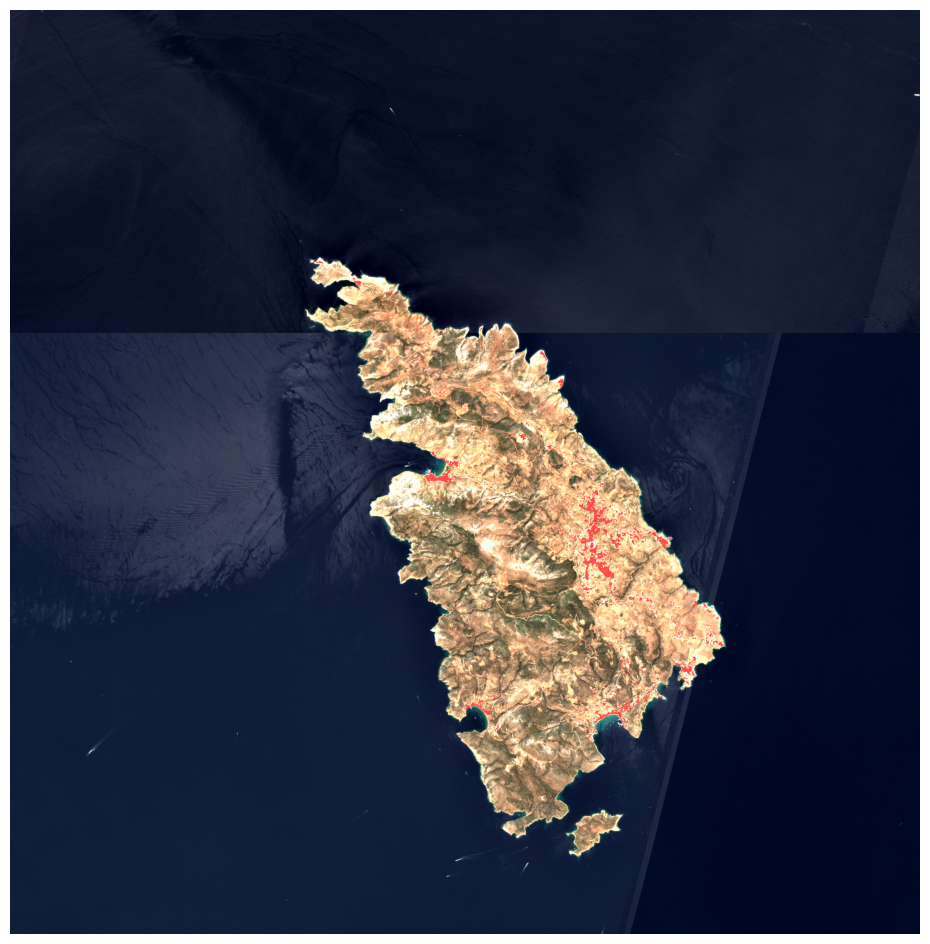

In [14]:
img = np.stack([s2_2021[2], s2_2021[1], s2_2021[0]], axis=-1).astype("float32")
low, high = np.percentile(img[img > 0], (2, 98))
img = np.clip((img - low) / (high - low), 0, 1)

plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.imshow(np.ma.masked_where(mask != 1, mask), cmap="autumn", alpha=0.7)   # orange = built-up
plt.axis("off")
plt.savefig(RESULTS / "qc_builtup_overlay_2021.png", dpi=200, bbox_inches="tight")
plt.show()

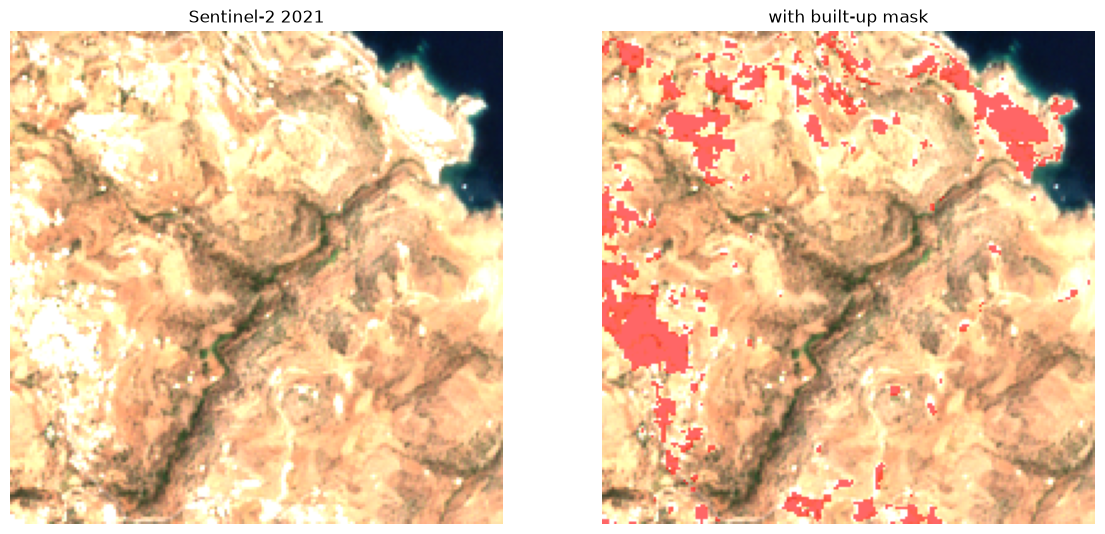

In [15]:
# find the 200 x 200 pixel block (2 km x 2 km) with the most built-up pixels
size = 200
best = (0, 0, 0)                                    # (number of built-up pixels, row, column)
for r in range(0, height - size, size):
    for c in range(0, width - size, size):
        n = int((mask[r:r+size, c:c+size] == 1).sum())
        if n > best[0]:
            best = (n, r, c)
_, r, c = best

# draw that block twice: plain, and with the mask on top
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img[r:r+size, c:c+size])
axes[0].set_title("Sentinel-2 2021")
axes[1].imshow(img[r:r+size, c:c+size])
axes[1].imshow(np.ma.masked_where(mask[r:r+size, c:c+size] != 1, mask[r:r+size, c:c+size]),
               cmap="autumn", alpha=0.6)
axes[1].set_title("with built-up mask")
for a in axes:
    a.axis("off")
plt.savefig(RESULTS / "qc_zoom_2021.png", dpi=200, bbox_inches="tight")
plt.show()

train | land pixels: 183982 | built-up pixels: 12200
validation | land pixels: 204740 | built-up pixels: 2535
test | land pixels: 380647 | built-up pixels: 6783


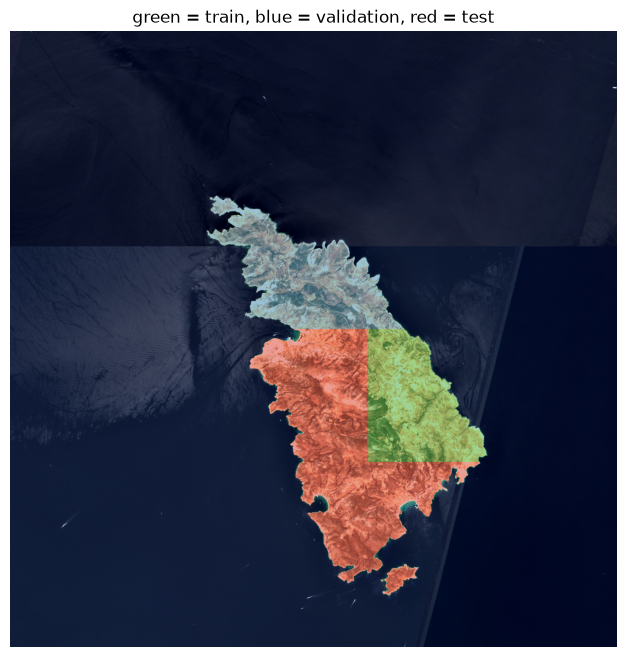

In [19]:
from matplotlib.colors import ListedColormap

split = np.zeros(mask.shape, dtype="uint8")      # like a new column filled with 0
split[:edges[1], :] = 2                          # north band -> validation
split[edges[1]:edges[2], cut:] = 1               # middle band, east half -> train
split[edges[1]:edges[2], :cut] = 3               # middle band, west half -> test
split[edges[2]:, :] = 3                          # south band -> test
split[mask == 255] = 0                           # sea stays 0

for k, name in [(1, "train"), (2, "validation"), (3, "test")]:
    print(name, "| land pixels:", int(((split == k)).sum()), "| built-up pixels:", int(((split == k) & (mask == 1)).sum()))

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.imshow(np.ma.masked_equal(split, 0), cmap=ListedColormap(["tab:green", "tab:blue", "tab:red"]),
           vmin=1, vmax=3, alpha=0.45)
plt.title("green = train, blue = validation, red = test")
plt.axis("off")
plt.savefig(RESULTS / "split_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
SIZE, STEP = 128, 64                      # chip = 128 x 128 pixels (1.28 km), moves 64 px each time
chips_dir = DATA / "processed" / "chips"
chips_dir.mkdir(parents=True, exist_ok=True)

counts = {1: 0, 2: 0}                     # 1 = train, 2 = validation
for r in range(0, height - SIZE + 1, STEP):
    for c in range(0, width - SIZE + 1, STEP):
        s = split[r:r+SIZE, c:c+SIZE]
        ids = np.unique(s[s > 0])         # which splits appear in this window (sea = 0 ignored)
        if len(ids) != 1 or ids[0] == 3:  # skip windows that mix splits, or belong to test
            continue
        if (s > 0).mean() < 0.3:          # skip windows that are mostly sea
            continue
        k = int(ids[0])
        name = "train" if k == 1 else "val"
        np.savez_compressed(chips_dir / f"{name}_{r}_{c}.npz",
                            image=s2_2021[:, r:r+SIZE, c:c+SIZE],
                            mask=mask[r:r+SIZE, c:c+SIZE])
        counts[k] += 1

print("train chips:", counts[1], "| validation chips:", counts[2])

train chips: 34 | validation chips: 47


train | chips: 34 | with any built-up: 34 | with >= 2% built-up: 28
val | chips: 47 | with any built-up: 43 | with >= 2% built-up: 3


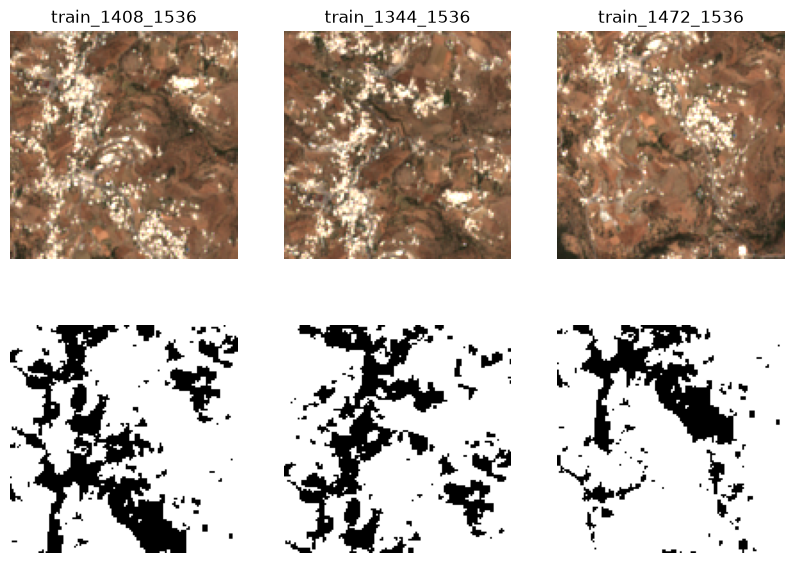

In [21]:
for name in ["train", "val"]:
    files = sorted(chips_dir.glob(f"{name}_*.npz"))
    share = [(np.load(f)["mask"] == 1).mean() for f in files]      # share of built-up pixels per chip
    print(name, "| chips:", len(files),
          "| with any built-up:", sum(s > 0 for s in share),
          "| with >= 2% built-up:", sum(s >= 0.02 for s in share))

# look at the 3 train chips with the most built-up pixels (top row = image, bottom row = mask)
files = sorted(chips_dir.glob("train_*.npz"))
best = sorted(files, key=lambda f: -(np.load(f)["mask"] == 1).sum())[:3]
fig, ax = plt.subplots(2, 3, figsize=(10, 7))
for i, f in enumerate(best):
    d = np.load(f)
    rgb = d["image"][[2, 1, 0]].transpose(1, 2, 0).astype(float)   # bands 3,2,1 = red, green, blue
    rgb = np.clip(rgb / np.percentile(rgb, 98), 0, 1)
    ax[0, i].imshow(rgb)
    ax[1, i].imshow(np.ma.masked_equal(d["mask"], 255), cmap="gray_r", vmin=0, vmax=1)
    ax[0, i].set_title(f.stem)
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.savefig(RESULTS / "qc_chips.png", dpi=150, bbox_inches="tight")
plt.show()